# ToM-ANFIS: Theory of Mind-Based Pedestrian Crossing Intention Prediction
# Subtractive Clustering Variant — SCANFIS

> *A cognitive AI framework that combines Theory of Mind feature extraction with a
> Subtractive-Clustering-initialised Adaptive Neuro-Fuzzy Inference System (SCANFIS)
> to produce explainable, human-aligned pedestrian crossing intention predictions
> for autonomous vehicles. Rules are generated directly from data-dense regions of
> the pedestrian cognitive state space, eliminating the combinatorial rule explosion
> of grid partitioning.*

---

## What This Notebook Does

Human drivers predict pedestrian behaviour by reasoning about **mental states** —
beliefs, goals, and attention — rather than raw pixels. ToM-ANFIS replicates
this process computationally. This notebook covers the full lifecycle:

1. Extract 10 Theory of Mind cognitive features from the PIE dataset
2. Run **subtractive clustering** on the training data to determine rules directly from data density
3. Train a SCANFIS model with a 5-layer neuro-fuzzy architecture
4. Tune hyperparameters — including the cluster radius `ra` — with Bayesian optimisation (Optuna)
5. Evaluate on held-out test data with regression and classification metrics
6. Generate explainable IF-THEN fuzzy rules for every prediction

---

## The 10 Theory of Mind Features

Features are grouped into four cognitive categories that mirror how human drivers
reason about pedestrians. **9 features serve as model inputs; G1 is the prediction target.**

### Belief States — *What does the pedestrian perceive about their environment?*
| Code | Feature Name | Range | Description |
|------|-------------|-------|-------------|
| **B1** | Age Vulnerability Awareness | [0.2, 0.8] | Self-perceived vulnerability from age: child=0.8, senior=0.7, adult=0.2, young=0.3 |
| **B2** | Intersection Complexity | [0.2, 1.0] | Cognitive load of road geometry: midblock=0.2, T-junction≈0.5, four-way=1.0 |
| **B3** | Position Proximity Awareness | [0.0, 1.0] | Normalised proximity to nearest crosswalk (1 = at crossing zone) |
| **B4** | Vehicle Density | [0.0, 1.0] | Average vehicle count over 15-frame window, normalised by max expected (10) |

### Goal States — *What does the pedestrian intend to do?*
| Code | Feature Name | Range | Description |
|------|-------------|-------|-------------|
| **G1** | Crossing Intention Strength | [0.0, 1.0] | ⬅ **PREDICTION TARGET** — crowdsourced ground-truth intention probability from PIE |
| **G2** | Urgency / Rushing Behaviour | [0.0, 1.0] | Time pressure: average of walking ratio and urgent-gesture ratio over window |

### Attention States — *Where does the pedestrian direct cognitive resources?*
| Code | Feature Name | Range | Description |
|------|-------------|-------|-------------|
| **A1** | Vehicle Awareness | [0.0, 1.0] | Fraction of frames where pedestrian gaze is directed at the ego-vehicle |
| **A2** | Traffic Signal Awareness | [−1.0, 1.0] | Safety score of attended signal: −1=no signal, 0=red/unsafe, 0.5=yellow, 1=green |

### Context / Environment — *What external factors constrain the decision?*
| Code | Feature Name | Range | Description |
|------|-------------|-------|-------------|
| **C1** | Relative Vehicle Speed | [0.0, 1.0] | Ego-vehicle OBD speed averaged over window, normalised to 27 m/s (≈100 km/h) |
| **C2** | Occlusion Factor | [0.0, 1.0] | Average occlusion level (0=fully visible, 1=fully occluded) over observation window |

---

## Full End-to-End Pipeline

### Part A — Feature Extraction Pipeline
```
PIE Dataset  (pie_database.pkl)
        │
        │   For each pedestrian clip:
        │   ┌──────────────────────────────────────────────────────┐
        │   │  Timeline:                                           │
        │   │  [└15 frame obs window┤][└30 frame horizon┤][✕] │
        │   │   B3,B4,G2,A1,A2,C1,C2      (aggregated)  crossing  │
        │   │   B1, B2, G1                (static attributes)      │
        │   └──────────────────────────────────────────────────────┘
        ▼
ToMFeatureExtractor
        │   Extracts 10 features per pedestrian
        │   Applies temporal aggregation (mean, ratio) over obs window
        ▼
tom_cognitive_features.csv      ← 1,842 pedestrians × 17 columns
                                   (7 metadata + 9 inputs + 1 target)
```

### Part B — Training Pipeline
```
tom_cognitive_features.csv
        │
        ▼
Data Preparation
        │   9 input features  ──→ MinMaxScaler → X ∈ [0,1]^9
        │   G1 (target)       ──→ y ∈ [0,1]
        │   Stratified split: 70% train | 15% val | 15% test
        ▼
Subtractive Clustering on X_train  (Chiu, 1994)
        │   For each point x_i: P_i = sum_j exp(-||x_i - x_j||^2 / (ra/2)^2)
        │   Highest-potential point -> cluster centre c_1
        │   Subtract c_1's influence, repeat -> c_2, c_3, ..., c_K
        │   K rules (typically 5-30) determined entirely by data density
        │   sigma_init = ra / sqrt(8)  per Chiu (1994)
        ▼
SCANFIS (K rules, data-driven)
        │
        │   Layer 1 - Per-rule Gaussian Fuzzification
        │     mu_k_i(x_i) = exp(-(x_i - c_k_i)^2 / (2 * sigma_k_i^2))
        │     Each rule has its OWN centre and sigma across all 9 features
        │     Learnable: K*F centres + K*F sigmas = 2*K*9 premise params
        │
        │   Layer 2 - Rule Firing (product T-norm, same as grid ANFIS)
        │     w_k = prod_i mu_k_i(x_i)
        │
        │   Layer 3 - Normalisation
        │     w_bar_k = w_k / (sum_k' w_k' + 1e-10)
        │
        │   Layer 4 - TSK Consequent
        │     f_k = p_k0 + sum_i p_ki * x_i   (K * 10 params)
        │
        │   Layer 5 - Defuzzification + Sigmoid
        │     y_hat = sigmoid(sum_k w_bar_k * f_k)  ->  y_hat in [0, 1]
        │
        │   Total params: 2*K*9 (premise) + K*10 (consequent) = K * 28
        │   e.g. K=15 rules -> 420 params  (vs 196,884 for grid ANFIS)
        ▼
Hybrid Loss Function
        │   L = MSE(y_hat, y) + alpha*BCE(y_hat, y_bin)
        │   Optimiser: Adam + gradient clipping (max_norm=1.0)
        │   Early stopping on validation MSE
        ▼
Optuna Bayesian Hyperparameter Tuning  (TPE sampler)
        │   Search space: ra in [0.15, 0.6]  <- controls rule count
        │                 lr in [1e-4, 1e-2]  |  batch in {32,64,128,256}
        │                 weight_decay in [1e-6, 1e-3]  |  patience in [10,30]
        │   Objective: minimise validation MSE
        ▼
Final SCANFIS Model  (retrained with best ra and hyperparameters)
        │   Saved: scanfis_model_optimized.pth + scaler_optimized.save
```

### Part C — Inference & Explainability Pipeline
```
New pedestrian observation
        │
        ▼
Extract 9 ToM features  ->  MinMaxScaler (loaded)  ->  X_scaled
        │
        ▼
SCANFIS Forward Pass  (K rules, e.g. K=15)
        │
        ├─── Output: y_hat in [0,1]  ->  Intention Level: LOW / MEDIUM / HIGH
        │           binary label: crossing (>=0.5) / not crossing (<0.5)
        │
        └─── Explainability:
               All K rules evaluated -> top fired rules extracted
               (K is small, typically 5-30, so ALL rules are readable)
               IF B1 is Low (0.14) AND A1 is High (0.81) AND G2 is Medium (0.52)
               THEN crossing intention is HIGH  (strength=0.312)
               ...
               Cluster-centre values printed alongside linguistic labels
               for full transparency (labels are approximate; numbers are exact)
```

## 1. Install Dependencies

`optuna` and `joblib` are the only non-standard packages not pre-installed in Colab's default runtime.
All other dependencies (PyTorch, scikit-learn, pandas, matplotlib) come pre-installed.

In [ ]:
!pip install -q optuna joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 12.9 MB/s eta 0:00:00


## 2. Import Libraries

All imports are consolidated in this single cell.

In [ ]:
# Standard library
import pickle
import itertools
from typing import Dict

# Data handling
import numpy as np
import pandas as pd
import joblib

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

# Deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F

# Hyperparameter optimisation
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)  # suppress per-trial verbose output

# Reproducibility seeds
torch.manual_seed(42)
np.random.seed(42)

print('All libraries imported')
print(f'  PyTorch  : {torch.__version__}')
print(f'  CUDA     : {torch.cuda.is_available()} '
      f'({torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only"})')
print(f'  Optuna   : {optuna.__version__}')

All libraries imported
  PyTorch  : 2.11.0+cu128
  CUDA     : True (Tesla T4)
  Optuna   : 4.9.0


## 3. Load PIE Dataset

### About the PIE Dataset
The **Pedestrian Intention Estimation (PIE)** dataset (Rasouli et al., ICCV 2019) is the
primary benchmark for this work. It contains:
- **1,842 pedestrian clips** from over 6 hours of ego-centric HD urban driving video
- **293,000+ labelled frames** across diverse intersection types
- Rich multimodal annotations per frame:
  - Pedestrian bounding boxes, age, crossing labels, intention probabilities
  - Behavioural annotations: action (standing/walking), gesture, gaze direction (look)
  - Traffic object annotations: vehicles, crosswalks, traffic lights with states
  - Occlusion level (0=fully visible, 1=partial, 2=fully occluded)
  - Ego-vehicle OBD sensor data: speed, heading

The dataset is distributed as a serialised Python dictionary (`pie_database.pkl`).
Upload it to your Google Drive before running the cell below.

### Database Structure
```
db
├── set01
│   ├── video_0001
│   │   ├── ped_annotations
│   │   │   └── 1_1_1
│   │   │       ├── frames       ← list of frame IDs
│   │   │       ├── bbox         ← [x1,y1,x2,y2] per frame
│   │   │       ├── occlusion    ← 0/1/2 per frame
│   │   │       ├── behavior     ← {action, gesture, look} per frame
│   │   │       └── attributes   ← {age, intersection, crossing_point,
│   │   │                           intention_prob, crossing, ...}
│   │   ├── traffic_annotations  ← vehicles, crosswalks, traffic lights
│   │   └── vehicle_annotations  ← OBD speed per frame
│   └── video_0002 ...
└── set02 ...
```

### Extract PIE annotations

#### Load Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load the PIE database
PIE_PATH = '/content/drive/MyDrive/pie_database.pkl'

with open(PIE_PATH, 'rb') as f:
    data = pickle.load(f)

db = data if isinstance(data, dict) else dict(data)

# Quick sanity check on database structure
total_videos = sum(len(db[s]) for s in db)
total_peds = sum(
    len(db[s][v]['ped_annotations'])
    for s in db for v in db[s]
)

print('PIE database loaded')
print(f'  Sets   : {list(db.keys())}')
print(f'  Videos : {total_videos}')
print(f'  Peds   : {total_peds}')

PIE database loaded
  Sets   : ['set01', 'set02', 'set03', 'set04', 'set05', 'set06']
  Videos : 53
  Peds   : 1842


In [ ]:
type(db)

dict

## 4. Theory of Mind Feature Extraction

### Motivation
When a human driver sees a pedestrian near a crosswalk, they don't just track movement -
they reason about mental states:
- *"Does the pedestrian see me?"* → Attention (A1)
- *"Are they in a hurry?"* → Goal urgency (G2)
- *"Is the light in their favour?"* → Attention to signals (A2)
- *"How busy is this intersection?"* → Belief about complexity (B2)

`ToMFeatureExtractor` formalises this reasoning into 10 computable features.

### Temporal Windowing
For each pedestrian, the extraction looks at a window of frames **ending 30 frames before the crossing event**:
```
──[start_idx]──────[end_idx = prediction_idx]──────[crossing_idx]──▶  time
  ←── obs_window (15 frames) ───►  ←── horizon (30 frames) ──►
```
- **Temporal features** (B3, B4, G2, A1, A2, C1, C2): aggregated (mean / ratio) over the 15-frame window
- **Static features** (B1, B2, G1): extracted once from pedestrian-level attributes

### 4.1  `ToMFeatureExtractor` Class

In [ ]:
class ToMFeatureExtractor:
    """
    Extract 10 Theory of Mind (ToM) cognitive features from the PIE database.

    Output columns per pedestrian:
        Metadata (7) : set_id, video_id, pedestrian_id, prediction_frame,
                       crossing_frame, frames_to_crossing, crossing_label
        Belief   (4) : B1, B2, B3, B4
        Goal     (2) : G1 (target), G2
        Attention(2) : A1, A2
        Context  (2) : C1, C2
    """

    def __init__(self, db: Dict, observation_window: int = 15):
        """
        Args:
            db               : PIE database dict loaded from pie_database.pkl
            observation_window: Number of frames to aggregate temporal features over
        """
        self.db       = db
        self.obs_window = observation_window

    # ── Shared utility helpers ─────────────────────────────────────────────

    def _bbox_center(self, bbox):
        return ((bbox[0] + bbox[2]) / 2, (bbox[1] + bbox[3]) / 2)

    def _bbox_dist(self, b1, b2):
        c1, c2 = self._bbox_center(b1), self._bbox_center(b2)
        return ((c1[0]-c2[0])**2 + (c1[1]-c2[1])**2) ** 0.5

    def _safe_mean(self, vals):
        return float(np.mean(vals)) if vals else 0.0

    # ── Belief State Features ─────────────────────────────────────────────

    def _B1(self, attributes: Dict) -> float:
        """
        B1: Age Vulnerability Awareness  ∈ [0.2, 0.8]  |  static
        Children and seniors have higher self-perceived vulnerability,
        making them more cautious (higher belief value) when crossing.
        """
        return {0: 0.8, 1: 0.3, 2: 0.2, 3: 0.7}.get(attributes.get('age', 2), 0.2)

    def _B2(self, attributes: Dict) -> float:
        """
        B2: Intersection Complexity  ∈ [0.2, 1.0]  |  static
        More complex intersections impose higher cognitive load on the pedestrian,
        requiring more careful observation before deciding to cross.
        """
        return {0: 0.2, 1: 0.5, 2: 0.6, 3: 0.6, 4: 1.0}.get(
            attributes.get('intersection', 0), 0.2)

    def _B3(self, ped_bbox, traffic_data, frame_id) -> float:
        """
        B3: Position Proximity Awareness  ∈ [0.0, 1.0]  |  frame-level
        Euclidean distance from pedestrian centre to the nearest crosswalk bbox centre,
        normalised by image width (1920px) and inverted so closer = higher value.
        Returns 0.0 if no crosswalk is annotated in the current frame.
        """
        try:
            min_d = float('inf')
            for obj in traffic_data.values():
                if obj['obj_class'] == 'crosswalk' and frame_id in obj['frames']:
                    cw_bbox = obj['bbox'][obj['frames'].index(frame_id)]
                    min_d = min(min_d, self._bbox_dist(ped_bbox, cw_bbox))
            return max(0.0, 1.0 - min(min_d / 1920.0, 1.0)) if min_d < float('inf') else 0.0
        except:
            return 0.0

    def _B4(self, traffic_data, frame_ids) -> float:
        """
        B4: Vehicle Density  ∈ [0.0, 1.0]  |  temporal
        Average number of annotated vehicles per frame over the observation window,
        capped at 1.0 using a normalisation factor of 10 vehicles.
        """
        try:
            counts = [
                sum(1 for o in traffic_data.values()
                    if o['obj_class'] == 'vehicle' and fid in o['frames'])
                for fid in frame_ids
            ]
            return min(self._safe_mean(counts) / 10.0, 1.0)
        except:
            return 0.0

    # ── Goal State Features ───────────────────────────────────────────────

    def _G1(self, attributes: Dict) -> float:
        """
        G1: Crossing Intention Strength  ∈ [0.0, 1.0]  |  static  ← TARGET
        Ground-truth intention probability from PIE's crowdsourced human annotations.
        This is the variable the ANFIS model is trained to predict.
        """
        return attributes.get('intention_prob', 0.5)

    def _G2(self, ped_data, frame_indices) -> float:
        """
        G2: Urgency / Rushing Behaviour  ∈ [0.0, 1.0]  |  temporal
        Average of two sub-signals over the observation window:
          - Walking ratio      : fraction of frames where action==1 (walking)
          - Urgent gesture ratio: fraction with gesture ∈ {1,2,3,4}
            (hand acknowledgment=1, hand yield=2, right-of-way=3, nod=4)
        """
        try:
            actions = [ped_data['behavior']['action'][i]  for i in frame_indices]
            gestures = [ped_data['behavior']['gesture'][i] for i in frame_indices]
            w = sum(a == 1         for a in actions)  / len(actions)
            g = sum(g in [1,2,3,4] for g in gestures) / len(gestures)
            return (w + g) / 2.0
        except:
            return 0.0

    # ── Attention State Features ──────────────────────────────────────────

    def _A1(self, ped_data, frame_indices) -> float:
        """
        A1: Vehicle Awareness  ∈ [0.0, 1.0]  |  temporal
        Proportion of observation frames in which the pedestrian gaze is
        directed toward the ego-vehicle (PIE 'look' annotation == 1).
        """
        try:
            return self._safe_mean([ped_data['behavior']['look'][i] for i in frame_indices])
        except:
            return 0.0

    def _A2(self, ped_data, traffic_data, frame_indices) -> float:
        """
        A2: Traffic Signal Awareness  ∈ [−1.0, 1.0]  |  temporal
        For each frame, finds visible traffic lights and maps their state to a
        pedestrian-safety score, then averages across the observation window.

        Signal state encoding:
          Pedestrian lights : green(3)=1.0 safe | yellow(2)=0.5 | red(1)=0.0 unsafe
          Vehicle lights    : red(1)=1.0 safe   | yellow(2)=0.5 | green(3)=0.0 unsafe
          Transit lights    : 0.0  |  No signal at all: −1.0
        """
        try:
            scores = []
            for idx in frame_indices:
                fid = ped_data['frames'][idx]
                for obj in traffic_data.values():
                    if obj.get('obj_class') == 'traffic_light' and fid in obj.get('frames', []):
                        state = obj['state'][obj['frames'].index(fid)]
                        tl_type = obj.get('obj_type', 'regular')
                        if tl_type == 'pedestrian': v = {0:-1, 1:0.0, 2:0.5, 3:1.0}.get(state,-1)
                        elif tl_type == 'transit':    v = 0.0
                        else:                         v = {0:-1, 1:1.0, 2:0.5, 3:0.0}.get(state,-1)
                        if v >= 0:
                            scores.append(v)
            return self._safe_mean(scores) if scores else -1.0
        except:
            return -1.0

    # ── Context / Environment Features ────────────────────────────────────

    def _C1(self, vehicle_data, frame_ids) -> float:
        """
        C1: Relative Vehicle Speed  ∈ [0.0, 1.0]  |  temporal
        Mean ego-vehicle OBD speed over the observation window, normalised
        by 27 m/s (≈100 km/h) which is the typical urban speed limit ceiling.
        Captures how threatening the traffic environment feels to the pedestrian.
        """
        try:
            speeds = [vehicle_data[fid].get('OBD_speed', 0.0) for fid in frame_ids if fid in vehicle_data]
            return min(np.mean(speeds) / 27.0, 1.0) if speeds else 0.0
        except:
            return 0.0

    def _C2(self, ped_data, frame_indices) -> float:
        """
        C2: Occlusion Factor  ∈ [0.0, 1.0]  |  temporal
        Average PIE occlusion annotation over the observation window,
        normalised from {0, 1, 2} to [0, 1] by dividing by 2.
        High occlusion limits both the pedestrian's and the AV's visibility.
        """
        try:
            return self._safe_mean([ped_data['occlusion'][i] for i in frame_indices]) / 2.0
        except:
            return 0.0

    # ── Main Extraction ───────────────────────────────────────────────────

    def extract_for_pedestrian(self, set_id, vid, ped_id, prediction_horizon=30):
        """
        Extract all 10 ToM features for a single pedestrian.

        Returns:
            dict with 7 metadata columns + 10 feature values, or None if
            the observation window cannot be constructed for this clip.
        """
        try:
            video_data = self.db[set_id][vid]
            ped_data = video_data['ped_annotations'][ped_id]
            traffic_data = video_data['traffic_annotations']
            vehicle_data = video_data['vehicle_annotations']
            attributes = ped_data['attributes']
            frames = ped_data['frames']

            # Locate crossing event and define temporal windows
            cp = attributes.get('crossing_point')
            if cp is None or cp not in frames:
                cp = frames[-1]
            crossing_idx = frames.index(cp)
            prediction_idx = max(0, crossing_idx - prediction_horizon)
            start_idx = max(0, prediction_idx - self.obs_window)

            if start_idx >= prediction_idx or prediction_idx > len(frames):
                return None

            frame_indices = list(range(start_idx, prediction_idx))
            current_idx = frame_indices[-1]
            current_frame = frames[current_idx]
            current_bbox = ped_data['bbox'][current_idx]
            frame_ids = [frames[i] for i in frame_indices]

            return {
                # Metadata
                'set_id': set_id, 'video_id': vid, 'pedestrian_id': ped_id,
                'prediction_frame': current_frame, 'crossing_frame': cp,
                'frames_to_crossing': crossing_idx - current_idx,
                'crossing_label': int(attributes.get('crossing', -1) == 1),
                # Belief
                'B1_age_vulnerability_awareness':   self._B1(attributes),
                'B2_intersection_complexity':       self._B2(attributes),
                'B3_pedestrian_position_proximity': self._B3(current_bbox, traffic_data, current_frame),
                'B4_vehicle_density':               self._B4(traffic_data, frame_ids),
                # Goal
                'G1_crossing_intention_strength':   self._G1(attributes),   # ← TARGET
                'G2_urgency_rushing':               self._G2(ped_data, frame_indices),
                # Attention
                'A1_vehicle_awareness':             self._A1(ped_data, frame_indices),
                'A2_traffic_signal_awareness':      self._A2(ped_data, traffic_data, frame_indices),
                # Context
                'C1_relative_vehicle_speed':        self._C1(vehicle_data, frame_ids),
                'C2_occlusion_factor':              self._C2(ped_data, frame_indices),
            }
        except Exception as e:
            print(f'  Skipping {set_id}/{vid}/{ped_id}: {e}')
            return None

    def extract_all(self, output_csv='tom_cognitive_features.csv',
                    prediction_horizon=30) -> pd.DataFrame:
        """
        Iterate over the full PIE database and extract features for every pedestrian.

        Args:
            output_csv         : Filename to save the resulting feature CSV.
            prediction_horizon : Frames before crossing to make the prediction.

        Returns:
            pd.DataFrame  (N_pedestrians × 17 columns)
        """
        all_rows, total, ok = [], 0, 0

        print('='*65)
        print('EXTRACTING ToM FEATURES FROM PIE DATABASE')
        print(f'  Observation window : {self.obs_window} frames')
        print(f'  Prediction horizon : {prediction_horizon} frames')
        print('='*65)

        for set_id in sorted(self.db):
            for vid in sorted(self.db[set_id]):
                for ped_id in sorted(self.db[set_id][vid]['ped_annotations']):
                    total += 1
                    row = self.extract_for_pedestrian(set_id, vid, ped_id, prediction_horizon)
                    if row:
                        all_rows.append(row)
                        ok += 1
                        if ok % 200 == 0:
                            print(f'  ✓ {ok}/{total} processed...')

        if not all_rows:
            print('No features extracted — verify database structure.')
            return pd.DataFrame()

        df = pd.DataFrame(all_rows)
        df.to_csv(output_csv, index=False)

        success_rate = 100 * ok / total
        print(f'\n  Pedestrians total  : {total}')
        print(f'  Successfully done  : {ok}  ({success_rate:.1f}%)')
        print(f'  Output CSV         : {output_csv}')
        print(f'  DataFrame shape    : {df.shape}')

        # Flag any near-zero variance features (could indicate extraction issues)
        feat_cols = [c for c in df.columns if c[0] in ('B','G','A','C')]
        low_var = [c for c in feat_cols if df[c].std() < 0.01]
        if low_var:
            print(f'\n  Low-variance features detected: {low_var}')
        else:
            print(f'\n  All {len(feat_cols)} features have healthy variance')

        return df

### 4.2 Run Feature Extraction

This iterates over all pedestrian clips, applies the 15-frame temporal window,
and saves the result to `tom_cognitive_features.csv`.
For the full PIE dataset (~1,842 pedestrians) this typically takes 2–5 minutes.

In [ ]:
extractor = ToMFeatureExtractor(db=db, observation_window=15)
df_features = extractor.extract_all(
    output_csv='tom_cognitive_features.csv',
    prediction_horizon=30
)
print(f'\nDone. Shape: {df_features.shape}')

EXTRACTING ToM FEATURES FROM PIE DATABASE
  Observation window : 15 frames
  Prediction horizon : 30 frames
  ✓ 200/202 processed...
  ✓ 400/404 processed...
  ✓ 600/606 processed...
  ✓ 800/808 processed...
  ✓ 1000/1013 processed...
  ✓ 1200/1223 processed...
  ✓ 1400/1426 processed...
  ✓ 1600/1629 processed...
  ✓ 1800/1830 processed...

  Pedestrians total  : 1842
  Successfully done  : 1812  (98.4%)
  Output CSV         : tom_cognitive_features.csv
  DataFrame shape    : (1812, 17)

  All 10 features have healthy variance

Done. Shape: (1812, 17)


## 5. Exploratory Data Analysis

Before training we inspect the extracted features to:
- Confirm there are **no missing values** (all extraction methods have safe fallbacks)
- Understand the **class distribution** of G1 and the binary crossing label (imbalance affects metrics)
- Check **inter-feature correlations** (correlated features provide redundant signal to the fuzzy rules)
- Visualise individual **feature distributions** to verify the extraction logic is sensible

In [ ]:
df_features.head()

,set_id,video_id,pedestrian_id,prediction_frame,crossing_frame,frames_to_crossing,crossing_label,B1_age_vulnerability_awareness,B2_intersection_complexity,B3_pedestrian_position_proximity,B4_vehicle_density,G1_crossing_intention_strength,G2_urgency_rushing,A1_vehicle_awareness,A2_traffic_signal_awareness,C1_relative_vehicle_speed,C2_occlusion_factor
0,set01,video_0001,1_1_1,1102,1133,31,0,0.2,1.0,0.791047,0.400000,0.966667,0.0,0.0,0.0,0.963222,0.0
1,set01,video_0001,1_1_10,16408,16439,31,0,0.2,1.0,0.702240,0.466667,0.850000,0.0,0.0,0.0,1.000000,1.0
2,set01,video_0001,1_1_11,16530,16561,31,0,0.2,1.0,0.669801,0.300000,0.950000,0.0,0.0,0.0,0.814805,0.0
3,set01,video_0001,1_1_12,17311,17342,31,0,0.2,0.2,0.000000,0.200000,0.083333,0.0,0.0,-1.0,1.000000,0.1
4,set01,video_0001,1_1_13,1175,1206,31,0,0.2,0.2,0.000000,0.426667,0.150000,0.0,1.0,0.0,1.000000,0.0


In [ ]:
df_features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1812 entries, 0 to 1811
Data columns (total 17 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   set_id                            1812 non-null   object 
 1   video_id                          1812 non-null   object 
 2   pedestrian_id                     1812 non-null   object 
 3   prediction_frame                  1812 non-null   int64  
 4   crossing_frame                    1812 non-null   int64  
 5   frames_to_crossing                1812 non-null   int64  
 6   crossing_label                    1812 non-null   int64  
 7   B1_age_vulnerability_awareness    1812 non-null   float64
 8   B2_intersection_complexity        1812 non-null   float64
 9   B3_pedestrian_position_proximity  1812 non-null   float64
 10  B4_vehicle_density                1812 non-null   float64
 11  G1_crossing_intention_strength    1812 non-null   float64
 12  G2_urg

In [ ]:
# Basic overview
df_features.describe().T


,count,mean,std,min,25%,50%,75%,max
prediction_frame,1812.0,9040.640177,5327.247018,97.0,4233.000000,8826.000000,13537.750000,20822.000000
crossing_frame,1812.0,9075.507174,5326.928236,128.0,4264.000000,8857.000000,13607.000000,20853.000000
frames_to_crossing,1812.0,31.000000,0.000000,31.0,31.000000,31.000000,31.000000,31.000000
crossing_label,1812.0,0.272075,0.445151,0.0,0.000000,0.000000,1.000000,1.000000
B1_age_vulnerability_awareness,1812.0,0.255850,0.159319,0.2,0.200000,0.200000,0.200000,0.800000
B2_intersection_complexity,1812.0,0.675938,0.345829,0.2,0.200000,0.600000,1.000000,1.000000
B3_pedestrian_position_proximity,1812.0,0.436777,0.353497,0.0,0.000000,0.601236,0.734654,0.982737
B4_vehicle_density,1812.0,0.195835,0.169275,0.0,0.100000,0.200000,0.300000,0.953333
G1_crossing_intention_strength,1812.0,0.709308,0.309365,0.0,0.533333,0.850000,0.950000,1.000000
G2_urgency_rushing,1812.0,0.177980,0.237719,0.0,0.000000,0.000000,0.500000,1.000000


--- EDA on df_features ---

Missing values per column:
set_id                              0
video_id                            0
pedestrian_id                       0
prediction_frame                    0
crossing_frame                      0
frames_to_crossing                  0
crossing_label                      0
B1_age_vulnerability_awareness      0
B2_intersection_complexity          0
B3_pedestrian_position_proximity    0
B4_vehicle_density                  0
G1_crossing_intention_strength      0
G2_urgency_rushing                  0
A1_vehicle_awareness                0
A2_traffic_signal_awareness         0
C1_relative_vehicle_speed           0
C2_occlusion_factor                 0
dtype: int64


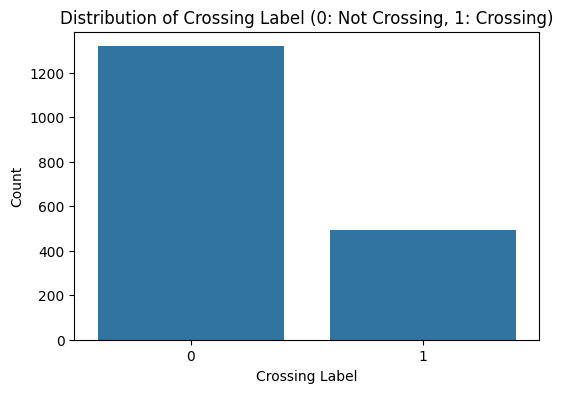

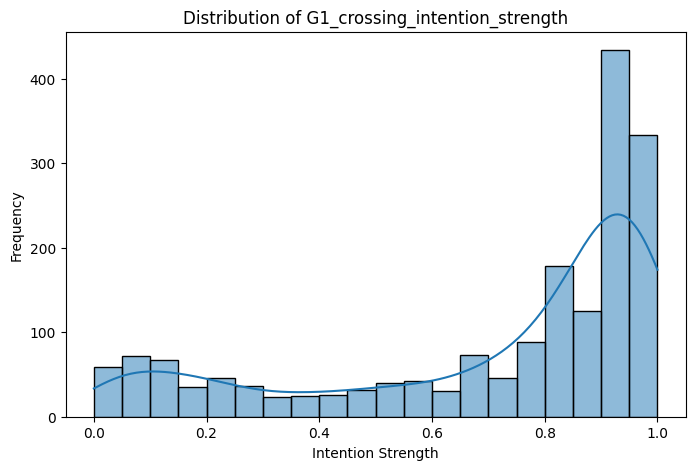

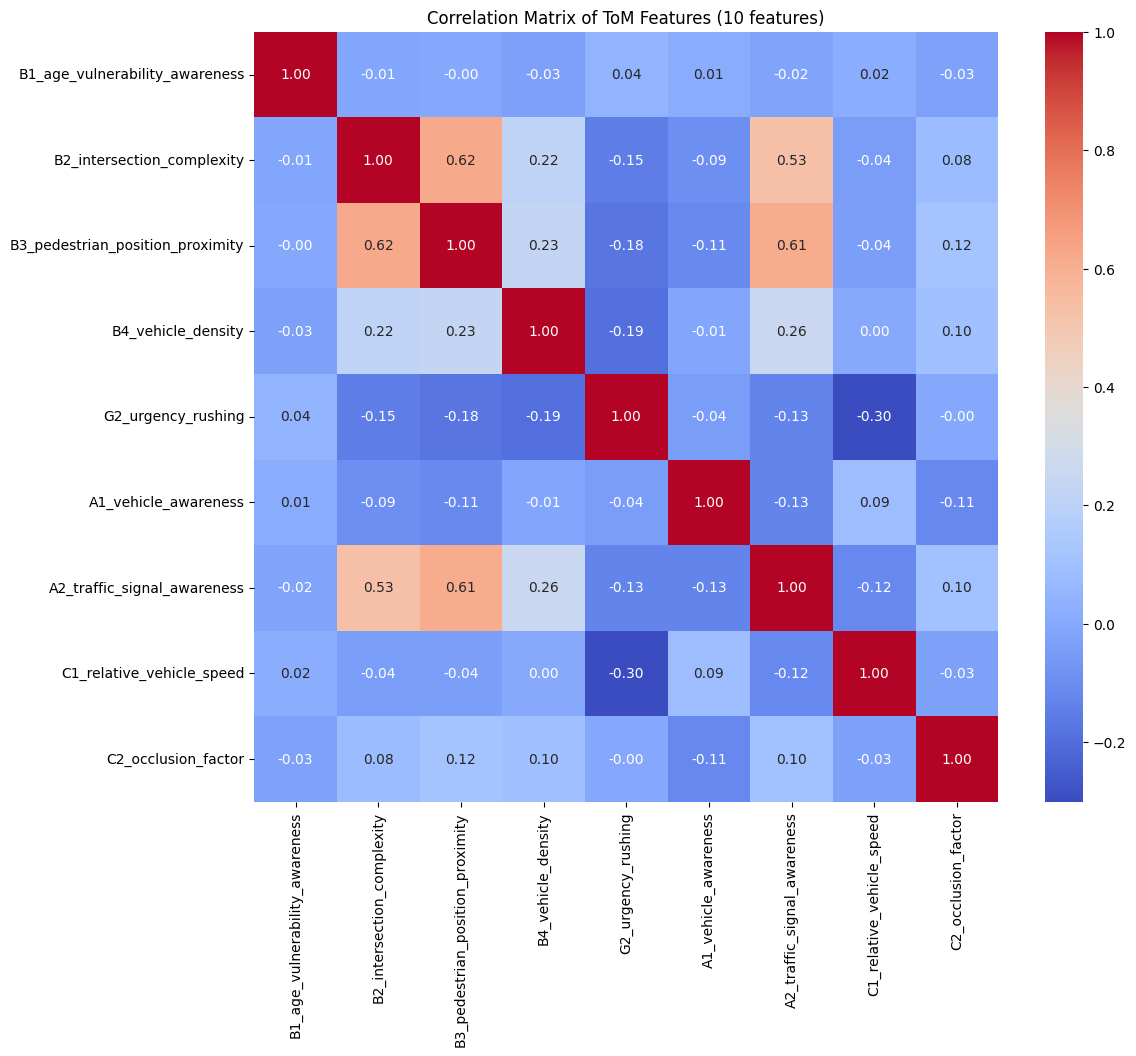


Visualizing feature distributions:

Histograms for numerical features:


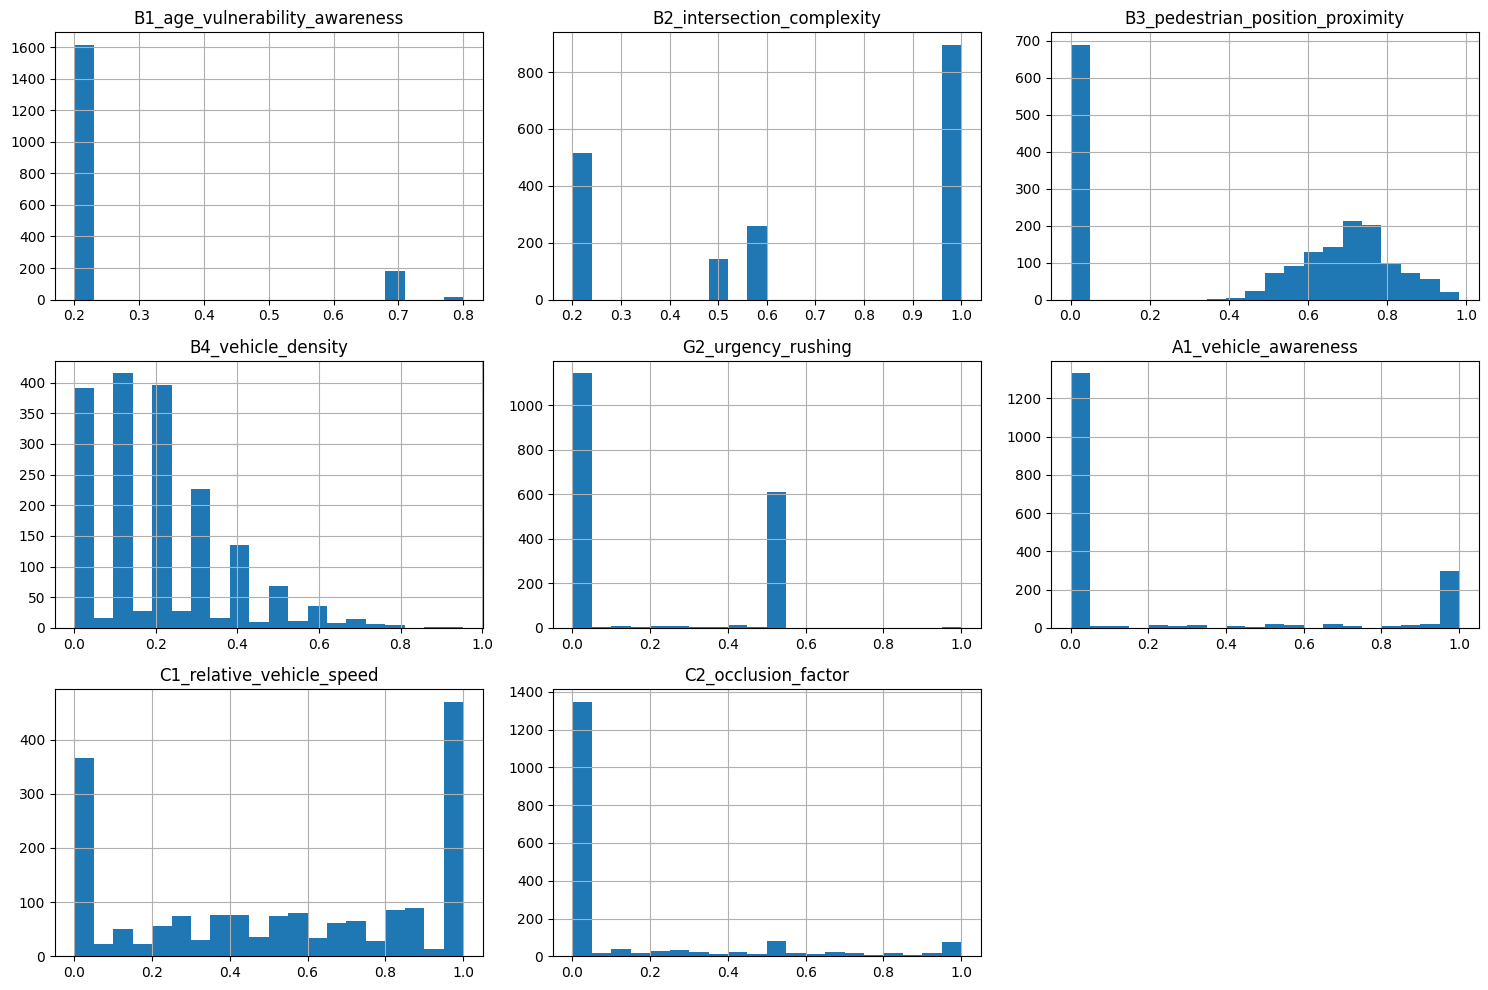


Bar plots for categorical features:


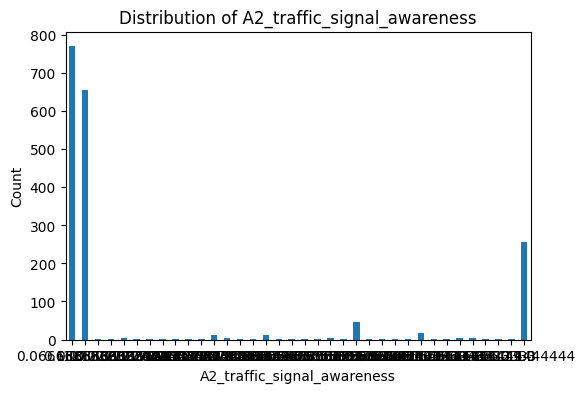


--- EDA Complete ---


In [ ]:
# --- Exploratory Data Analysis (EDA) ---

print("--- EDA on df_features ---")

# Check for missing values
print("\nMissing values per column:")
print(df_features.isnull().sum())

# Check the distribution of the target variable ('crossing_label')
plt.figure(figsize=(6, 4))
sns.countplot(x='crossing_label', data=df_features)
plt.title('Distribution of Crossing Label (0: Not Crossing, 1: Crossing)')
plt.xlabel('Crossing Label')
plt.ylabel('Count')
plt.show()

# Check the distribution of the target variable ('G1_crossing_intention_strength')
plt.figure(figsize=(8, 5))
sns.histplot(df_features['G1_crossing_intention_strength'], bins=20, kde=True)
plt.title('Distribution of G1_crossing_intention_strength')
plt.xlabel('Intention Strength')
plt.ylabel('Frequency')
plt.show()

# Select only the feature columns for correlation analysis (exclude G1 target)
feature_cols = [col for col in df_features.columns if col.startswith(('B', 'G', 'A', 'C')) and col != 'G1_crossing_intention_strength']

# Calculate and visualize the correlation matrix
plt.figure(figsize=(12, 10))
correlation_matrix = df_features[feature_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of ToM Features (10 features)')
plt.show()

# Visualize distributions of features
print("\nVisualizing feature distributions:")

# Identify numerical and categorical features (based on your 11 features)
numerical_features = [
    'B1_age_vulnerability_awareness',
    'B2_intersection_complexity',
    'B3_pedestrian_position_proximity',
    'B4_vehicle_density',
    'G2_urgency_rushing',
    'A1_vehicle_awareness',
    'C1_relative_vehicle_speed',
    'C2_occlusion_factor'
]

categorical_features = [
    'A2_traffic_signal_awareness',  # Has discrete values -1, 0, 0.5, 1
]

# Plot histograms for numerical features
print("\nHistograms for numerical features:")
df_features[numerical_features].hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

# Plot bar plots for categorical features
print("\nBar plots for categorical features:")
for col in categorical_features:
    plt.figure(figsize=(6, 4))
    df_features[col].value_counts().sort_index().plot(kind='bar')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=0)
    plt.show()

print("\n--- EDA Complete ---")

## 6. ANFIS Model Definition — Subtractive Clustering Variant

### Why Subtractive Clustering Instead of Grid Partitioning

Grid partitioning enumerates every possible Low / Medium / High combination
across 9 features: $3^9 = 19{,}683$ rules, regardless of whether real
pedestrians actually occupy those regions of input space. Subtractive
clustering inverts this: it looks at where the **training data is dense**
and places exactly one rule per dense region. If the data naturally separates
into $K$ distinct cognitive patterns (typically 5 – 30 for real-world
behavioural data), you get exactly $K$ rules — not 19,683.

### Subtractive Clustering Algorithm (Chiu, 1994)

**Step 1 — Potential computation.**
Every training sample $x_i$ is treated as a candidate cluster centre.
Its potential is defined as the sum of its Gaussian-weighted proximity
to every other point:

$$
P_i = \sum_{j=1}^{N} \exp\!\left( -\frac{\|x_i - x_j\|^2}{(r_a/2)^2} \right)
$$

- $P_i$ — potential of data point $i$; higher means more neighbours nearby
- $x_i, x_j$ — any two data points in the $F$-dimensional feature space
- $\|x_i - x_j\|^2$ — squared Euclidean distance between them
- $r_a$ — **cluster radius**: the single most important hyperparameter.
  Small $r_a$ $\to$ many small, tight clusters $\to$ many rules.
  Large $r_a$ $\to$ few large, broad clusters $\to$ few rules.
  Typical range for $[0,1]$-scaled data: $0.15$ – $0.6$.
- The denominator $(r_a/2)^2$ means any point further than $r_a/2$ from
  $x_i$ contributes less than $e^{-1} \approx 0.37$ to $P_i$.

**Step 2 — First centre selection.**
The point with the highest potential $P^* = \max_i P_i$ becomes the first
cluster centre $c_1 = x_{i^*}$.

**Step 3 — Potential subtraction.**
To prevent the next centre from being placed too close to $c_1$,
subtract $c_1$'s influence from every remaining point using a larger
squash radius $r_b = \eta \cdot r_a$ (default $\eta = 1.25$):

$$
P_i \leftarrow P_i - P^* \cdot \exp\!\left( -\frac{\|x_i - c_1\|^2}{(r_b/2)^2} \right)
$$

- $P^*$ — potential of the just-accepted centre
- $r_b$ — squash radius, wider than $r_a$ to create a no-go zone
  around each accepted centre so rules don't pile up in the same region
- $\eta = 1.25$ by default; larger $\eta$ means centres must be further apart

**Step 4 — Iterate.**
Return to Step 2. The point now holding the highest potential becomes
centre $c_2$. Repeat until no remaining point's potential exceeds
the accept threshold $\epsilon_a \cdot P_1$ (default $\epsilon_a = 0.5$),
where $P_1$ is the very first cluster's potential.

**Step 5 — Rule extraction.**
Each cluster centre $c_k \in \mathbb{R}^F$ becomes exactly **one fuzzy rule**.
The cluster radius $r_a$ gives the initial width of the Gaussian membership
function for that rule via:

$$
\sigma_{k,i} = \frac{r_a}{\sqrt{8}}
$$

- $\sigma_{k,i}$ — standard deviation of the Gaussian MF for rule $k$,
  feature $i$, initialised identically across all features
- $\frac{r_a}{\sqrt{8}}$ is the standard derivation from Chiu (1994),
  such that at distance $r_a$ from the centre, the membership value
  drops to $e^{-1} \approx 0.37$
- Both centres and sigmas become **learnable parameters** during ANFIS
  training; the clustering only provides their initialisation

### SCANFIS Five-Layer Architecture

Layers 2 – 5 are structurally identical to the grid ANFIS.
Only Layer 1 changes: each rule has its own unique centre across all
$F = 9$ features simultaneously, rather than selecting from 3 shared
linguistic terms per feature via Cartesian product.

**Layer 1 — Per-rule Gaussian Fuzzification**

$$
\mu_{k,i}(x_i) = \exp\!\left( -\frac{(x_i - c_{k,i})^2}{2\,\sigma_{k,i}^2} \right)
$$

- $\mu_{k,i}(x_i) \in [0, 1]$ — membership of input $x_i$ in rule $k$'s
  antecedent for feature $i$
- $c_{k,i}$ — learnable centre of rule $k$ for feature $i$ (initialised
  from the $k$-th cluster centre's $i$-th coordinate)
- $\sigma_{k,i}$ — learnable width of rule $k$ for feature $i$
  (initialised from $r_a / \sqrt{8}$)
- Each rule has its **own** $(c_{k,i}, \sigma_{k,i})$ pair — there is no
  shared Low/Medium/High structure. Rules are not built by selecting
  from categories; their centres come directly from the data clusters.

**Layer 2 — Rule Firing (product T-norm)**

$$
w_k = \prod_{i=1}^{F} \mu_{k,i}(x_i)
$$

- $w_k \in [0, 1]$ — unnormalised firing strength of rule $k$
- $F = 9$ — number of input features
- Product T-norm: if any single feature is a poor match for rule $k$,
  the entire firing strength collapses toward zero

**Layer 3 — Normalisation**

$$
\bar{w}_k = \frac{w_k}{\displaystyle\sum_{k'=1}^{K} w_{k'} + \varepsilon}
$$

- $\bar{w}_k$ — normalised firing strength; all $\bar{w}_k$ sum to 1
- $K$ — total number of active rules (data-driven, typically 5–30)
- $\varepsilon = 10^{-10}$ — small constant to prevent division by zero

**Layer 4 — Takagi-Sugeno-Kang (TSK) Consequent**

$$
f_k = p_{k0} + \sum_{i=1}^{F} p_{ki}\, x_i
$$

- $f_k$ — output of rule $k$'s consequent function
- $p_{k0}$ — learnable bias term for rule $k$
- $p_{ki}$ — learnable weight for feature $i$ in rule $k$'s consequent
- This is a first-order TSK system: each rule's output is a linear
  function of the inputs, not a constant (zeroth-order)

**Layer 5 — Defuzzification and Sigmoid**

$$
\hat{y} = \sigma\!\left( \sum_{k=1}^{K} \bar{w}_k\, f_k \right), \quad
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

- $\hat{y} \in [0, 1]$ — predicted crossing intention probability
- The weighted sum aggregates all rule outputs proportional to how
  strongly each rule fired for this input
- $\sigma$ maps the aggregated output to $[0, 1]$ for probability
  interpretation

In [ ]:
def subtractive_clustering(X: np.ndarray, ra: float = 0.4,
                           squash_factor: float = 1.25,
                           accept_ratio: float = 0.5,
                           reject_ratio: float = 0.15,
                           max_clusters: int = 100):
    """
    Chiu's subtractive clustering algorithm [1] for data-driven fuzzy rule
    generation. Each resulting cluster becomes exactly one ANFIS rule,
    eliminating the combinatorial rule explosion of grid partitioning.

    Args:
        X             : (N, F) array, expected to be scaled to [0, 1]
        ra            : Cluster radius. Smaller -> more clusters/rules.
                         Larger -> fewer clusters/rules. Typical range
                         for [0,1]-scaled data: 0.15 - 0.6.
        squash_factor : Multiplier on ra for the neighbourhood used to
                         suppress potential around an accepted centre
                         (rb = squash_factor * ra). Default 1.25 [3].
        accept_ratio  : A candidate point is accepted unconditionally if
                         its potential exceeds accept_ratio * P1_max.
        reject_ratio  : A candidate point is rejected outright if its
                         potential falls below reject_ratio * P1_max.
        max_clusters  : Hard safety cap on the number of clusters found.

    Returns:
        centers : (K, F) array of cluster centres -> rule antecedents
        ra_used : float, the cluster radius used (for sigma derivation)
    """
    N, F = X.shape
    rb = squash_factor * ra

    # Pairwise squared distances -> potential for every point
    diff = X[:, None, :] - X[None, :, :]              # (N, N, F)
    sq_dist = (diff ** 2).sum(axis=2)                  # (N, N)
    potential = np.exp(-sq_dist / ((ra / 2) ** 2)).sum(axis=1)  # (N,)

    centers = []
    first_potential = None

    for _ in range(max_clusters):
        idx = int(np.argmax(potential))
        p_star = potential[idx]

        if first_potential is None:
            first_potential = p_star
        if p_star <= 0:
            break

        if p_star > accept_ratio * first_potential:
            accept = True
        elif p_star < reject_ratio * first_potential:
            break
        else:
            # Borderline candidate: accept only if far enough from
            # existing centres relative to its potential
            if centers:
                d_min = np.min(np.linalg.norm(
                    np.array(centers) - X[idx], axis=1))
                accept = (d_min / ra + p_star / first_potential) >= 1.0
            else:
                accept = True

        if accept:
            centers.append(X[idx].copy())
            # Subtract this centre's influence from all potentials
            sq_d = ((X - X[idx]) ** 2).sum(axis=1)
            potential -= p_star * np.exp(-sq_d / ((rb / 2) ** 2))
            potential = np.clip(potential, 0, None)
        else:
            # Reject this point permanently and try the next-highest
            potential[idx] = 0.0

    return np.array(centers), ra


class SCANFIS(nn.Module):
    """
    Subtractive-Clustering-initialised Adaptive Neuro-Fuzzy Inference System.

    Structurally identical to the grid ANFIS in Layers 2-5 (product T-norm
    rule firing, normalisation, TSK consequent, sigmoid defuzzification).
    The only architectural difference is Layer 1: instead of 3 shared
    membership functions per feature combined via Cartesian product into
    3^9 rules, each rule has its own unique centre across all 9 features,
    taken directly from a cluster found by subtractive_clustering().

    API compatibility guarantee: predict_explain() and global_rules() return
    the SAME dict structure as the grid ANFIS class, so downstream code
    (FastAPI backend, inference notebook) works without modification.

    Reference: Chiu (1994) [1], Mohan Rao et al. (2015) [2]
    """

    def __init__(self, cluster_centers: np.ndarray, ra: float,
                 feature_names: list = None):
        """
        Args:
            cluster_centers : (K, F) array from subtractive_clustering()
            ra              : Cluster radius used to derive sigma
            feature_names   : Feature name strings for explainability
        """
        super().__init__()
        self.in_features   = cluster_centers.shape[1]
        self.num_rules      = cluster_centers.shape[0]
        self.feature_names = feature_names or [f'Feature_{i}' for i in range(self.in_features)]

        # Premise parameters - per-rule, per-feature centre and sigma
        # (NOT shared across rules, unlike grid ANFIS's GaussianMF)
        self.centers = nn.Parameter(
            torch.tensor(cluster_centers, dtype=torch.float32)
        )                                                    # (K, F)

        sigma_init = ra / np.sqrt(8)                          # Chiu (1994) [1]
        self.sigmas = nn.Parameter(
            torch.full((self.num_rules, self.in_features), sigma_init,
                       dtype=torch.float32)
        )                                                    # (K, F)

        # TSK consequent - one first-order linear function per rule
        self.consequent_weights = nn.Parameter(
            torch.randn(self.num_rules, self.in_features + 1) * 0.5
        )

        total = sum(p.numel() for p in self.parameters())
        print(f'SCANFIS initialised  |  Rules: {self.num_rules}  |  Params: {total:,}')

    def _to_linguistic(self, value: float) -> str:
        """Map a continuous [0,1] value to its nearest linguistic term."""
        if value < 0.33:
            return 'Low'
        elif value < 0.67:
            return 'Medium'
        return 'High'

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, device = x.shape[0], x.device

        # L1 - Fuzzification: per-rule, per-feature Gaussian membership
        diff  = x.unsqueeze(1) - self.centers.unsqueeze(0)          # (B, K, F)
        sigma = torch.abs(self.sigmas.unsqueeze(0)) + 1e-6          # (1, K, F)
        mu    = torch.exp(-0.5 * (diff / sigma) ** 2)               # (B, K, F)

        # L2 - Rule firing: product T-norm across features (same as grid ANFIS)
        w = mu.prod(dim=2)                                          # (B, K)

        # L3 - Normalisation (identical to grid ANFIS)
        w_bar = w / (w.sum(dim=1, keepdim=True) + 1e-10)

        # L4 - TSK consequents (identical to grid ANFIS)
        x_aug = torch.cat([x, torch.ones(B, 1, device=device)], dim=1)
        f_k   = torch.matmul(x_aug, self.consequent_weights.T)      # (B, K)

        # L5 - Defuzzification + sigmoid (identical to grid ANFIS)
        return torch.sigmoid((w_bar * f_k).sum(dim=1, keepdim=True))

    # ── Explainability: identical API to grid ANFIS ─────────────────

    def global_rules(self, top_k: int = 10):
        """
        Rank all rules by average |consequent weight| and return the
        top-k as human-readable IF-THEN strings.

        IDENTICAL signature and return format to grid ANFIS.global_rules().
        """
        importance = self.consequent_weights.abs().mean(dim=1)
        top_idx    = importance.argsort(descending=True)[:top_k]
        fn         = self.feature_names
        centers_np = self.centers.detach().cpu().numpy()
        rules      = []
        for idx in top_idx:
            r    = idx.item()
            ante = ' AND '.join(
                f'{fn[i]} is {self._to_linguistic(centers_np[r, i])}'
                for i in range(self.in_features)
            )
            w    = self.consequent_weights[r].detach().cpu().numpy()
            body = f'{w[0]:.3f}' + ''.join(
                f' + {w[i+1]:.3f}·{fn[i]}' for i in range(self.in_features)
            )
            rules.append((importance[idx].item(),
                          f'IF {ante}\n   THEN intention = {body}'))
        return rules

    def predict_explain(self, x_sample: np.ndarray, threshold: float = 0.0001):
        """
        Run inference on a single sample and return the prediction with
        all fired rules as natural-language IF-THEN strings.

        IDENTICAL signature and return format to grid ANFIS.predict_explain().
        """
        self.eval()
        device     = next(self.parameters()).device
        x_t        = torch.FloatTensor(x_sample).unsqueeze(0).to(device)
        fn         = self.feature_names
        centers_np = self.centers.detach().cpu().numpy()

        with torch.no_grad():
            pred  = self(x_t).item()
            diff  = x_t.unsqueeze(1) - self.centers.unsqueeze(0)
            sigma = torch.abs(self.sigmas.unsqueeze(0)) + 1e-6
            mu    = torch.exp(-0.5 * (diff / sigma) ** 2)
            w     = mu.prod(dim=2)
            w_bar = (w / (w.sum(dim=1, keepdim=True) + 1e-10)).squeeze(0)

            x_aug = torch.cat([x_t, torch.ones(1, 1, device=device)], dim=1)
            f_k   = torch.matmul(x_aug, self.consequent_weights.T).squeeze(0)

        level = 'LOW' if pred < 0.33 else ('MEDIUM' if pred < 0.67 else 'HIGH')

        fired = []
        for k in range(self.num_rules):
            fs = w_bar[k].item()
            if fs > threshold:
                ante = ' AND '.join(
                    f'{fn[i]} is {self._to_linguistic(centers_np[k, i])}'
                    for i in range(self.in_features)
                )
                cv  = torch.sigmoid(f_k[k]).item()
                clv = 'LOW' if cv < 0.33 else ('MEDIUM' if cv < 0.67 else 'HIGH')
                fired.append({
                    'rule_id'              : k,
                    'firing_strength'      : fs,
                    'rule'                 : f'IF {ante} THEN crossing intention is {clv}',
                    'consequent_value'     : cv,
                    'consequent_linguistic': clv,
                })

        fired.sort(key=lambda r: r['firing_strength'], reverse=True)
        return {'probability': pred, 'intention_level': level, 'fired_rules': fired}

## 7. Data Preparation

### Feature Selection
- **9 inputs** : B1, B2, B3, B4, G2, A1, A2, C1, C2
- **1 target** : G1 (crossing intention strength, continuous ∈ [0,1])

### Normalisation
`MinMaxScaler` maps each input feature to [0, 1] before clustering and training.
This is critical for subtractive clustering to work correctly: the cluster
radius `ra` is a single value applied uniformly across all 9 dimensions, so
features must be on comparable scales. Without normalisation, a feature with
range [0, 100] would dominate the Euclidean distance calculation in the
potential function, and `ra` would have no meaningful geometric interpretation.
After normalisation, `ra = 0.3` means the same physical neighbourhood size
in every feature dimension.

### Train / Validation / Test Split
- **70% train** — subtractive clustering runs on this set, and the model is trained here
- **15% val** — early stopping and Optuna hyperparameter search
- **15% test** — held-out, never seen during clustering, training, or tuning

Stratified on the binary crossing label to preserve class balance in all splits.

> **Note:** subtractive clustering is run on `X_train` only — not the full dataset.
> Running it on the full dataset would leak validation and test set information
> into the rule structure, violating the train/val/test separation.

In [ ]:
def prepare_data(csv_path: str):
    """
    Load the feature CSV, normalise inputs, and return arrays ready for training.

    Returns:
        X_scaled      (N, 9)  - MinMax-normalised input features
        y             (N, 1)  - G1 crossing intention probabilities
        feature_names list    - column names for the 9 inputs
        scaler                - fitted MinMaxScaler (save for inference)
    """
    df = pd.read_csv(csv_path)

    feature_names = [
        'B1_age_vulnerability_awareness',
        'B2_intersection_complexity',
        'B3_pedestrian_position_proximity',
        'B4_vehicle_density',
        'G2_urgency_rushing',
        'A1_vehicle_awareness',
        'A2_traffic_signal_awareness',
        'C1_relative_vehicle_speed',
        'C2_occlusion_factor',
    ]

    X = df[feature_names].values
    y = df['G1_crossing_intention_strength'].values.reshape(-1, 1)

    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X)

    cross_pct = (y >= 0.5).mean() * 100
    print(f'Loaded {X.shape[0]} samples  |  {X.shape[1]} input features')
    print(f'  G1 range      : [{y.min():.3f}, {y.max():.3f}]')
    print(f'  Class balance : {cross_pct:.1f}% crossing  |  '
          f'{100-cross_pct:.1f}% not crossing')
    return X_scaled, y, feature_names, scaler


# Load and split
X, y, feature_names, scaler = prepare_data('tom_cognitive_features.csv')

# 70 / 15 / 15 stratified split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=(y > 0.5).astype(int)
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42,
    stratify=(y_temp > 0.5).astype(int)
)

print(f'\nSplit  →  Train: {len(X_train)}  |  Val: {len(X_val)}  |  Test: {len(X_test)}')
print(f'Device →  {"CUDA: " + torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

Loaded 1812 samples  |  9 input features
  G1 range      : [0.000, 1.000]
  Class balance : 76.8% crossing  |  23.2% not crossing

Split  →  Train: 1268  |  Val: 272  |  Test: 272
Device →  CUDA: Tesla T4


## 8. Training and Evaluation Functions

### Training Design Choices

**Gradient clipping** (`max_norm=1.0`): TSK consequent parameters receive
gradients proportional to the number of active rules. During early epochs,
before firing strengths have stabilised, these gradients can spike.
Clipping prevents exploding gradients without requiring an aggressively
small learning rate.

**Early stopping**: Monitors validation MSE and restores the best
checkpoint when patience epochs pass without improvement. Prevents
the model from memorising the training set after the consequent weights
have converged.

**Mini-batch DataLoader**: Mini-batch stochastic gradient descent
generalises better than full-batch updates. Necessary for training
efficiency given the ~1,300 training samples.

### Loss Function

A hybrid objective balances regression accuracy and binary classification
reliability:

$$
\mathcal{L} = \underbrace{\frac{1}{N}\sum_{n=1}^{N}(\hat{y}_n - y_n)^2}_{\text{MSE (regression)}}
+ \;\alpha \underbrace{\left[-\frac{1}{N}\sum_{n=1}^{N}\Big(y_n^{\text{bin}}\log\hat{y}_n
+ (1-y_n^{\text{bin}})\log(1-\hat{y}_n)\Big)\right]}_{\text{BCE (classification)}}
$$

- $\hat{y}_n \in [0,1]$ — predicted crossing intention probability for sample $n$
- $y_n \in [0,1]$ — ground-truth G1 intention probability (continuous)
- $y_n^{\text{bin}} = \mathbf{1}[y_n > 0.5]$ — binarised label for the BCE term
- $\alpha$ — BCE weight coefficient; controls how strongly binary
  classification consistency is enforced alongside regression accuracy
- $N$ — batch size

### Evaluation Metrics

Two sets of metrics are reported after training:

**Regression** (RMSE, MAE, R²): measures how well the model tracks the
continuous G1 probability value, not just the binary decision.

**Classification** (Accuracy, Precision, Recall, F1) at a 0.5 threshold:
measures binary crossing / not-crossing decisions.

In [ ]:
def train_anfis(model, X_train, y_train, X_val, y_val,
                epochs=200, lr=0.01, batch_size=64,
                patience=25, weight_decay=1e-5, bce_weight=0.01):
    """
    Train the ANFIS model using a hybrid MSE + BCE loss with early stopping.

    Args:
        epochs       : Maximum training epochs
        lr           : Adam learning rate
        batch_size   : Mini-batch size
        patience     : Epochs without val improvement before stopping
        weight_decay : L2 regularisation coefficient (Adam's weight_decay = λ)
        bce_weight   : α coefficient weighting the BCE classification term

    Returns:
        trained model, list of train losses, list of val losses
    """
    device = next(model.parameters()).device
    optimiser = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    # Build DataLoader for mini-batch training
    ds = torch.utils.data.TensorDataset(
        torch.FloatTensor(X_train).to(device),
        torch.FloatTensor(y_train).to(device)
    )
    loader = torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=True)

    X_val_t = torch.FloatTensor(X_val).to(device)
    y_val_t = torch.FloatTensor(y_val).to(device)

    train_losses, val_losses          = [], []
    best_val, patience_count, best_st = float('inf'), 0, None

    print('='*65)
    print(f'TRAINING  |  lr={lr:.2e}  batch={batch_size}  '
          f'wd={weight_decay:.2e}  patience={patience}')
    print('='*65)

    for epoch in range(epochs):
        # ── Training pass ──
        model.train()
        epoch_loss = 0.0
        for bX, by in loader:
            optimiser.zero_grad()
            pred = model(bX)
            loss = F.mse_loss(pred, by)                         # regression
            loss += bce_weight * F.binary_cross_entropy(pred, (by > 0.5).float())
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimiser.step()
            epoch_loss += loss.item()
        train_loss = epoch_loss / len(loader)

        # ── Validation pass ──
        model.eval()
        with torch.no_grad():
            val_loss = F.mse_loss(model(X_val_t), y_val_t).item()

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        # ── Early stopping ──
        if val_loss < best_val:
            best_val, patience_count = val_loss, 0
            best_st = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            patience_count += 1

        if (epoch + 1) % 20 == 0:
            print(f'  Epoch {epoch+1:>3}/{epochs}  '
                  f'train={train_loss:.4f}  val={val_loss:.4f}'
                  f'  patience={patience_count}/{patience}')

        if patience_count >= patience:
            print(f'  ↳ Early stopping at epoch {epoch+1}')
            break

    if best_st:
        model.load_state_dict(best_st)
    print(f'  Best val loss: {best_val:.4f}')
    return model, train_losses, val_losses


def evaluate_anfis(model, X_test, y_test):
    """
    Evaluate the trained ANFIS on the held-out test set.

    Computes:
      Regression    : RMSE, MAE, R²
      Classification: Accuracy, Precision, Recall, F1  (threshold=0.5)
      Confusion matrix: TN, FP, FN, TP

    Returns:
        dict with all metrics and the raw predictions array
    """
    device = next(model.parameters()).device
    model.eval()
    with torch.no_grad():
        preds = model(torch.FloatTensor(X_test).to(device)).cpu().numpy()

    # Regression
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    # Classification at 0.5 threshold
    y_bin = (y_test >= 0.5).astype(int)
    p_bin = (preds   >= 0.5).astype(int)
    acc = accuracy_score(y_bin, p_bin)
    prec = precision_score(y_bin, p_bin, zero_division=0)
    rec = recall_score(y_bin, p_bin, zero_division=0)
    f1 = f1_score(y_bin, p_bin, zero_division=0)
    cm = confusion_matrix(y_bin, p_bin)

    print('='*50)
    print('TEST SET RESULTS')
    print('='*50)
    print(f'  Regression:')
    print(f'    RMSE : {rmse:.4f}')
    print(f'    MAE  : {mae:.4f}')
    print(f'    R²   : {r2:.4f}')
    print(f'  Classification (threshold=0.5):')
    print(f'    Accuracy  : {acc:.4f}')
    print(f'    Precision : {prec:.4f}')
    print(f'    Recall    : {rec:.4f}')
    print(f'    F1-Score  : {f1:.4f}')
    print(f'  Confusion Matrix:')
    print(f'    TN={cm[0,0]:>4}  FP={cm[0,1]:>4}')
    print(f'    FN={cm[1,0]:>4}  TP={cm[1,1]:>4}')

    return {'predictions': preds, 'rmse': rmse, 'mae': mae, 'r2': r2,
            'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1,
            'confusion_matrix': cm}


def plot_results(train_losses, val_losses, y_test, predictions, results, title=''):
    """Four-panel diagnostic dashboard: loss curves, scatter, residuals, distributions."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Loss curves
    axes[0,0].plot(train_losses, label='Train', linewidth=1.5)
    axes[0,0].plot(val_losses,   label='Validation', linewidth=1.5)
    axes[0,0].set(title='Loss Curves (MSE)', xlabel='Epoch', ylabel='MSE Loss')
    axes[0,0].legend(); axes[0,0].grid(alpha=0.3)

    # Predicted vs Ground Truth
    axes[0,1].scatter(y_test, predictions, alpha=0.35, s=15, color='steelblue')
    axes[0,1].plot([0,1],[0,1],'r--', lw=1.5, label='Perfect')
    axes[0,1].set(title=f'Predicted vs Ground Truth  (R²={results["r2"]:.3f})',
                  xlabel='Ground Truth G1', ylabel='Predicted ŷ')
    axes[0,1].legend(); axes[0,1].grid(alpha=0.3)

    # Residuals
    residuals = y_test - predictions
    axes[1,0].scatter(predictions, residuals, alpha=0.35, s=15, color='darkorange')
    axes[1,0].axhline(0, color='r', lw=1.5, linestyle='--')
    axes[1,0].set(title='Residual Plot', xlabel='Predicted ŷ', ylabel='Residual (y − ŷ)')
    axes[1,0].grid(alpha=0.3)

    # Distribution comparison
    axes[1,1].hist(y_test,      bins=30, alpha=0.5, label='Ground Truth', color='steelblue')
    axes[1,1].hist(predictions, bins=30, alpha=0.5, label='Predictions',  color='darkorange')
    axes[1,1].set(title='Intention Probability Distribution',
                  xlabel='Intention Probability', ylabel='Frequency')
    axes[1,1].legend()

    suptitle = f'ToM-ANFIS Evaluation{" — " + title if title else ""}'
    plt.suptitle(suptitle, fontsize=13, y=1.01)
    plt.tight_layout()
    fname = f'anfis_results{"_" + title.replace(" ","_") if title else ""}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    print(f'Saved {fname}')
    plt.show()

## 9. Baseline Model Training

Before running Optuna, we train a SCANFIS with a hand-picked starting
cluster radius $r_a = 0.3$ and default training hyperparameters.
This serves two purposes:

1. **Sanity check** — confirms the subtractive clustering step produces
   a reasonable number of rules and the model trains without errors
   before committing to 100 Optuna trials.
2. **Reference baseline** — gives a concrete starting performance number
   to compare the Optuna-tuned model against in Section 11.

The choice of $r_a = 0.3$ is a reasonable midpoint for $[0,1]$-scaled
data: it typically produces 8–50 rules, which is interpretable while
still being expressive enough to capture the main pedestrian cognitive
patterns. Optuna will search the full range $[0.15, 0.6]$ in Section 10.

Subtractive clustering found 26 clusters (rules) with ra=0.3
SCANFIS initialised  |  Rules: 26  |  Params: 728
TRAINING  |  lr=1.00e-02  batch=64  wd=1.00e-05  patience=25
  Epoch  20/200  train=0.0482  val=0.0552  patience=16/25
  Epoch  40/200  train=0.0480  val=0.0543  patience=4/25
  Epoch  60/200  train=0.0465  val=0.0542  patience=16/25
  Epoch  80/200  train=0.0473  val=0.0543  patience=18/25
  Epoch 100/200  train=0.0486  val=0.0533  patience=14/25
  ↳ Early stopping at epoch 111
  Best val loss: 0.0517
TEST SET RESULTS
  Regression:
    RMSE : 0.2160
    MAE  : 0.1576
    R²   : 0.5270
  Classification (threshold=0.5):
    Accuracy  : 0.8640
    Precision : 0.9065
    Recall    : 0.9194
    F1-Score  : 0.9129
  Confusion Matrix:
    TN=  41  FP=  20
    FN=  17  TP= 194
Saved anfis_results_Baseline_(Subtractive_Clustering).png


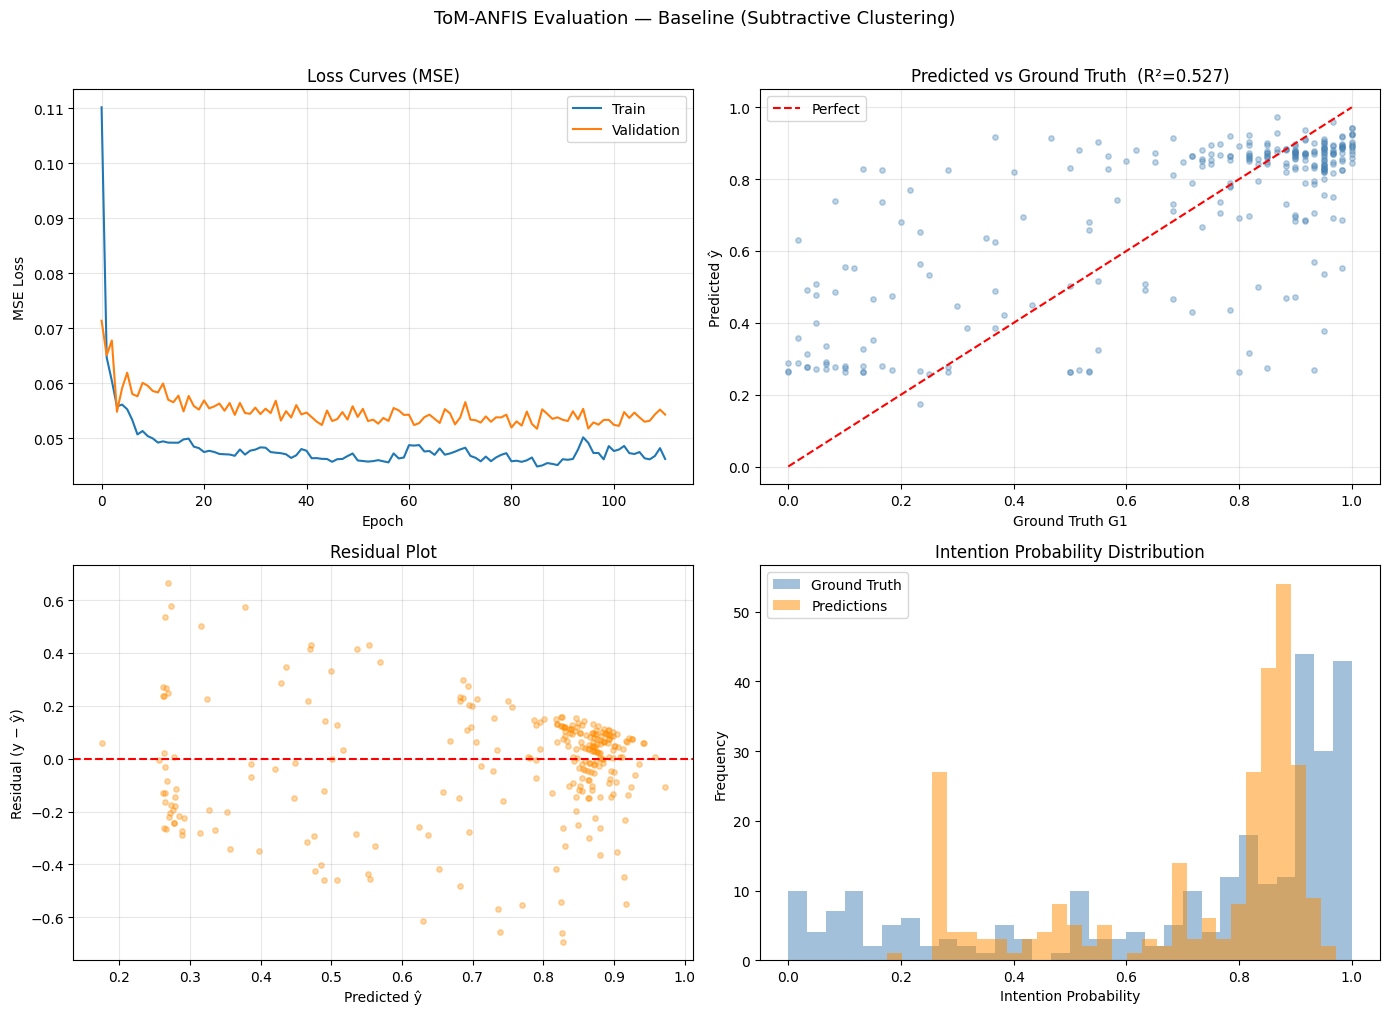

Saved scanfis_model.pth  +  scaler.save


In [ ]:
# Run subtractive clustering on the training data to determine rule count and antecedents
INITIAL_RA = 0.3  # starting cluster radius - smaller = more rules, larger = fewer rules

cluster_centers, ra_used = subtractive_clustering(X_train, ra=INITIAL_RA)
print(f'Subtractive clustering found {len(cluster_centers)} clusters (rules) '
      f'with ra={ra_used}')

baseline_model = SCANFIS(
    cluster_centers=cluster_centers,
    ra=ra_used,
    feature_names=feature_names
).to(device)

baseline_model, train_losses_b, val_losses_b = train_anfis(
    baseline_model, X_train, y_train, X_val, y_val,
    epochs=200, lr=0.01, batch_size=64, patience=25
)

baseline_results = evaluate_anfis(baseline_model, X_test, y_test)
plot_results(train_losses_b, val_losses_b,
             y_test, baseline_results['predictions'],
             baseline_results, title='Baseline (Subtractive Clustering)')

torch.save({'model_state_dict': baseline_model.state_dict(),
            'cluster_centers': cluster_centers, 'ra': ra_used,
            'feature_names': feature_names}, 'scanfis_model.pth')
joblib.dump(scaler, 'scaler.save')
print('Saved scanfis_model.pth  +  scaler.save')

## 10. Hyperparameter Tuning with Optuna

### Why Bayesian Optimisation?

Grid search across 5 hyperparameters with even modest resolution would
require hundreds of training runs. Optuna's **Tree-structured Parzen
Estimator (TPE)** models the objective function probabilistically:
it maintains a surrogate model of which hyperparameter regions produce
good results and directs sampling toward those regions, converging to
good configurations in far fewer trials than exhaustive search.

### Search Space

| Hyperparameter | Range | Scale | What it controls |
|---|---|---|---|
| $r_a$ (cluster radius) | $[0.15,\ 0.6]$ | uniform | Number of rules generated — the most important parameter here |
| Learning rate $\eta$ | $[10^{-4},\ 10^{-2}]$ | log-uniform | Step size for Adam optimiser |
| Batch size | $\{32, 64, 128, 256\}$ | categorical | Gradient noise vs. compute speed |
| Weight decay $\lambda$ | $[10^{-6},\ 10^{-3}]$ | log-uniform | L2 regularisation on consequent weights |
| Patience | $[10, 30]$ | integer | Early stopping tolerance in epochs |

$r_a$ is the most architecturally significant parameter: it determines
**how many rules exist**, not just how well they are tuned. A trial with
$r_a = 0.15$ might produce 40 rules; $r_a = 0.5$ might produce 6.
Optuna explores both extremes and everything in between, finding the
$r_a$ that best balances expressiveness and simplicity.

### Objective Metric

Minimise the **lowest validation MSE** seen across all training epochs
for a given trial. This rewards both convergence quality and stability
(a trial that reaches a good loss and holds it beats one that briefly
dips low then diverges).

In [ ]:
def objective(trial: optuna.Trial) -> float:
    """
    Optuna objective function for the subtractive clustering variant.
    Each trial re-runs subtractive clustering with a candidate ra, builds
    a fresh SCANFIS with the resulting rule count, trains it, and returns
    the best (minimum) validation MSE achieved.
    """
    ra           = trial.suggest_uniform('ra', 0.15, 0.6)
    lr           = trial.suggest_loguniform('lr',           1e-4, 1e-2)
    batch_size   = trial.suggest_categorical('batch_size',  [32, 64, 128, 256])
    weight_decay = trial.suggest_loguniform('weight_decay', 1e-6, 1e-3)
    patience     = trial.suggest_int('patience',            10, 30)

    cluster_centers, ra_used = subtractive_clustering(X_train, ra=ra)

    # Guard against degenerate ra values producing too few/many rules
    if len(cluster_centers) < 2 or len(cluster_centers) > 200:
        return float('inf')

    model = SCANFIS(cluster_centers, ra_used, feature_names).to(device)

    _, _, val_losses_trial = train_anfis(
        model, X_train, y_train, X_val, y_val,
        epochs=250, lr=lr, batch_size=batch_size,
        patience=patience, weight_decay=weight_decay
    )
    return min(val_losses_trial)

In [ ]:
print('='*65)
print('STARTING OPTUNA HYPERPARAMETER SEARCH  (100 trials)')
print('='*65)

study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42)
)
study.optimize(objective, n_trials=100, show_progress_bar=True)

best = study.best_trial
print('\nOPTUNA COMPLETE')
print(f'  Trials finished      : {len(study.trials)}')
print(f'  Best validation loss : {best.value:.4f}')
print(f'  Best hyperparameters :')
for k, v in best.params.items():
    print(f'    {k:20s}: {v}')

best_lr = best.params['lr']
best_ra = best.params['ra']
best_batch_size = best.params['batch_size']
best_weight_decay = best.params['weight_decay']
best_patience = best.params['patience']

STARTING OPTUNA HYPERPARAMETER SEARCH  (100 trials)


  0%|          | 0/100 [00:00<?, ?it/s]

SCANFIS initialised  |  Rules: 24  |  Params: 672
TRAINING  |  lr=7.97e-03  batch=32  wd=1.49e-06  patience=28


/tmp/ipykernel_1699/3625260438.py:8: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  ra           = trial.suggest_uniform('ra', 0.15, 0.6)
/tmp/ipykernel_1699/3625260438.py:9: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  lr           = trial.suggest_loguniform('lr',           1e-4, 1e-2)
/tmp/ipykernel_1699/3625260438.py:11: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  weight_decay = trial.suggest_loguniform('weight_decay', 1e-6, 1e-3)


  Epoch  20/250  train=0.0507  val=0.0602  patience=15/28
  ↳ Early stopping at epoch 33
  Best val loss: 0.0557
SCANFIS initialised  |  Rules: 13  |  Params: 364
TRAINING  |  lr=2.61e-03  batch=64  wd=3.51e-06  patience=13
  Epoch  20/250  train=0.0520  val=0.0591  patience=2/13
  Epoch  40/250  train=0.0484  val=0.0555  patience=2/13
  ↳ Early stopping at epoch 51
  Best val loss: 0.0553
SCANFIS initialised  |  Rules: 26  |  Params: 728
TRAINING  |  lr=1.12e-03  batch=128  wd=7.52e-06  patience=17
  Epoch  20/250  train=0.0640  val=0.0723  patience=3/17
  Epoch  40/250  train=0.0508  val=0.0603  patience=1/17
  Epoch  60/250  train=0.0482  val=0.0589  patience=2/17
  Epoch  80/250  train=0.0465  val=0.0581  patience=12/17
  ↳ Early stopping at epoch 85
  Best val loss: 0.0577
SCANFIS initialised  |  Rules: 18  |  Params: 504
TRAINING  |  lr=3.72e-03  batch=128  wd=6.65e-05  patience=13
  Epoch  20/250  train=0.0519  val=0.0629  patience=3/13
  ↳ Early stopping at epoch 30
  Best val 

## 11. Retrain with Best Hyperparameters

Using the Optuna-optimised configuration, we re-run subtractive clustering
with the best $r_a$ to obtain the final rule antecedents, then train
the final SCANFIS model from scratch with the best learning rate,
batch size, and weight decay.

Note that clustering is re-run here (not reused from Section 9) because
the Optuna-discovered $r_a$ is likely different from the initial $0.3$,
and the rule count and centre positions come entirely from the clustering
step — so a different $r_a$ produces a structurally different model.

The final model is evaluated on the held-out test set and compared
against the Section 9 baseline to quantify the improvement from
hyperparameter tuning.

TRAINING FINAL SCANFIS WITH BEST OPTUNA HYPERPARAMETERS
Final clustering: 17 rules with ra=0.3710881205827763
SCANFIS initialised  |  Rules: 17  |  Params: 476
TRAINING  |  lr=6.50e-03  batch=128  wd=3.07e-04  patience=29
  Epoch  20/250  train=0.0460  val=0.0552  patience=0/29
  Epoch  40/250  train=0.0446  val=0.0554  patience=7/29
  Epoch  60/250  train=0.0438  val=0.0538  patience=7/29
  Epoch  80/250  train=0.0433  val=0.0553  patience=4/29
  Epoch 100/250  train=0.0429  val=0.0521  patience=14/29
  Epoch 120/250  train=0.0418  val=0.0522  patience=19/29
  ↳ Early stopping at epoch 130
  Best val loss: 0.0500
TEST SET RESULTS
  Regression:
    RMSE : 0.2053
    MAE  : 0.1487
    R²   : 0.5726
  Classification (threshold=0.5):
    Accuracy  : 0.8676
    Precision : 0.9070
    Recall    : 0.9242
    F1-Score  : 0.9155
  Confusion Matrix:
    TN=  41  FP=  20
    FN=  16  TP= 195
Saved anfis_results_Optuna_Optimised_(Subtractive_Clustering).png


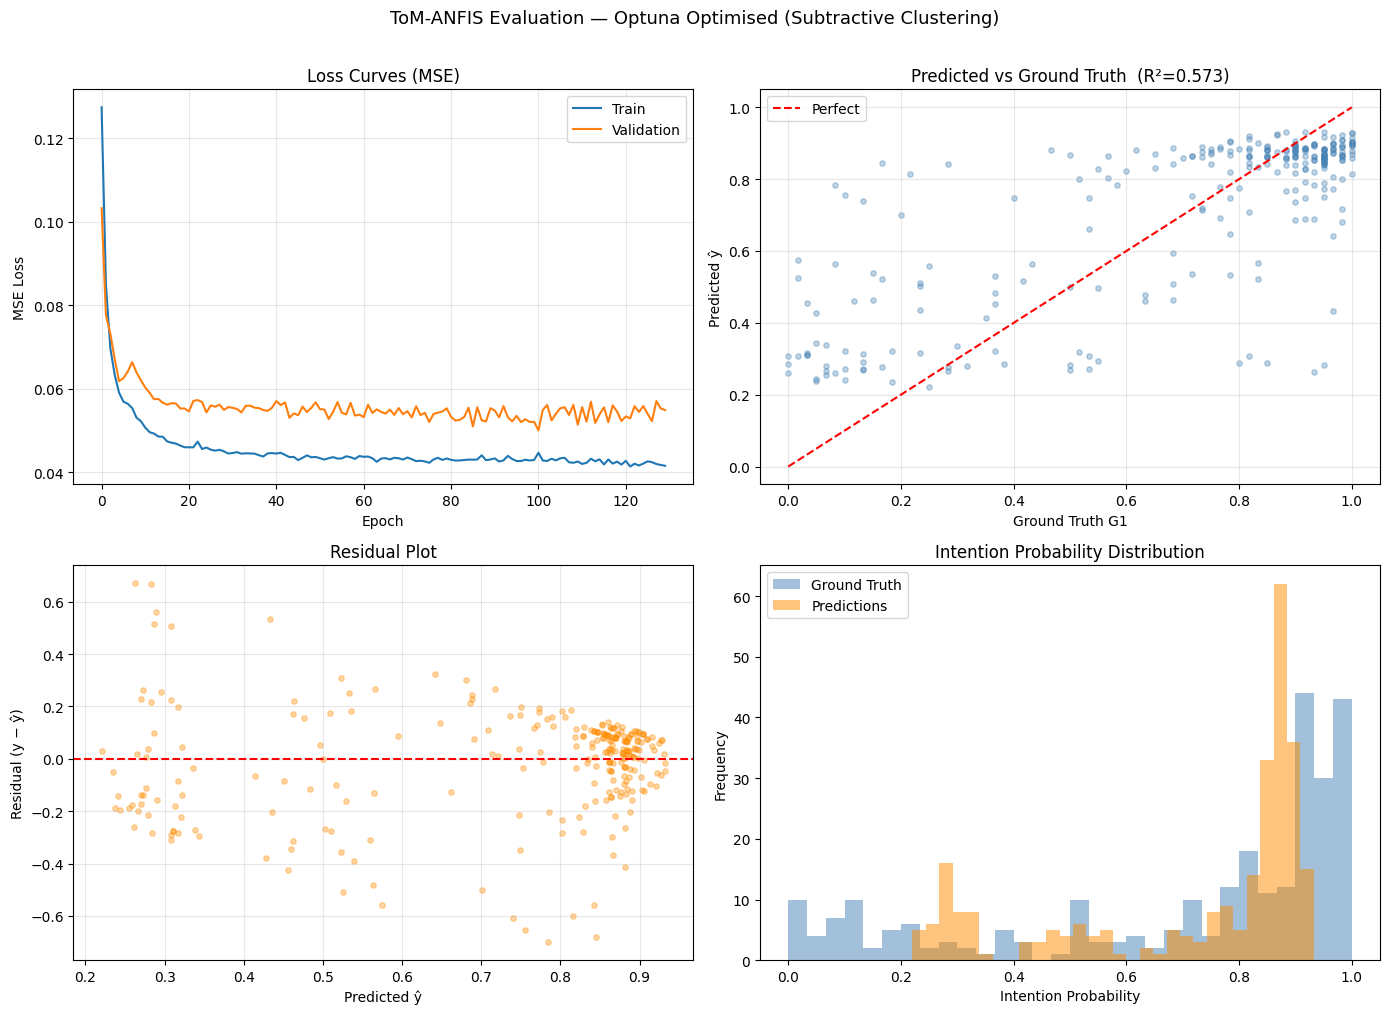


BASELINE vs FINAL COMPARISON
  Metric          Baseline       Final       Delta
------------------------------------------------
  accuracy          0.8640      0.8676  +   0.0037
  precision         0.9065      0.9070  +   0.0004
  recall            0.9194      0.9242  +   0.0047
  f1                0.9129      0.9155  +   0.0026
  rmse              0.2160      0.2053    -0.0107
  r2                0.5270      0.5726  +   0.0455

Rule count: 17  (vs. 19,683 for grid partitioning)


In [ ]:
print('='*65)
print('TRAINING FINAL SCANFIS WITH BEST OPTUNA HYPERPARAMETERS')
print('='*65)

cluster_centers_final, ra_final = subtractive_clustering(X_train, ra=best_ra)
print(f'Final clustering: {len(cluster_centers_final)} rules with ra={ra_final}')

final_model = SCANFIS(
    cluster_centers=cluster_centers_final,
    ra=ra_final,
    feature_names=feature_names
).to(device)

final_model, train_losses_f, val_losses_f = train_anfis(
    final_model, X_train, y_train, X_val, y_val,
    epochs=250,
    lr=best_lr,
    batch_size=best_batch_size,
    patience=best_patience,
    weight_decay=best_weight_decay
)

final_results = evaluate_anfis(final_model, X_test, y_test)
plot_results(train_losses_f, val_losses_f,
             y_test, final_results['predictions'],
             final_results, title='Optuna Optimised (Subtractive Clustering)')

print('\nBASELINE vs FINAL COMPARISON')
print(f"  {'Metric':<12}  {'Baseline':>10}  {'Final':>10}  {'Delta':>10}")
print('-'*48)
for m in ['accuracy', 'precision', 'recall', 'f1', 'rmse', 'r2']:
    b = baseline_results[m]; f = final_results[m]
    sign = '+' if f > b else ''
    print(f'  {m:<12}  {b:>10.4f}  {f:>10.4f}  {sign}{f-b:>9.4f}')

print(f'\nRule count: {final_model.num_rules}  (vs. 19,683 for grid partitioning)')

## 12. Explainability — Fuzzy Rule Analysis

### Global vs Local Explanations

**Global explanations** reveal which rules the SCANFIS model has learned
to weight heavily across all samples — showing the model's general
strategy for predicting crossing intention. Importance is measured as
the mean absolute value of a rule's TSK consequent weight vector:

$$
\text{importance}_k = \frac{1}{F+1} \sum_{i=0}^{F} |p_{ki}|
$$

- $p_{ki}$ — consequent weight for rule $k$, feature $i$
- $F = 9$ — number of input features ($+1$ for the bias $p_{k0}$)
- Rules with large $\text{importance}_k$ have large output contributions
  when they fire

**Local explanations** show which specific rules fired for a particular
pedestrian observation, giving a transparent reasoning chain for that
individual prediction. Because SCANFIS has far fewer rules than the
grid model, the active rule list per prediction is short and readable.

**Important note on rule labels:** unlike the grid ANFIS where
'B1 is Low' referred to a trained, shared linguistic category,
SCANFIS labels (Low / Medium / High) are derived by mapping each
rule's continuous cluster-centre value to the nearest third of $[0,1]$.
They are approximate descriptors for readability, not trained categories.
The printed cluster-centre value alongside the label is the precise number.

### Why This Is More Interpretable Than the Grid Model

With only $K$ rules (typically 5–30 from subtractive clustering),
a domain expert can read **every single rule** and verify it makes
cognitive sense. This was not possible with 19,683 grid rules
even after pruning to 50, because the rules still carried the
Low/Medium/High abstraction without showing the actual numeric region
of input space each rule covers. SCANFIS rules are grounded directly
in data-dense regions of the pedestrian cognitive state space.

In [ ]:
# Global rule importance — top 10 rules
print('='*65)
print('GLOBAL RULE ANALYSIS — Top 10 Rules by Importance')
print('='*65)

rules = final_model.global_rules(top_k=10)
for rank, (importance, rule_text) in enumerate(rules, 1):
    print(f'\n[Rule {rank}]  importance = {importance:.4f}')
    print(f'  {rule_text}')

GLOBAL RULE ANALYSIS — Top 10 Rules by Importance

[Rule 1]  importance = 0.4728
  IF B1_age_vulnerability_awareness is Low AND B2_intersection_complexity is Low AND B3_pedestrian_position_proximity is Low AND B4_vehicle_density is Low AND G2_urgency_rushing is Low AND A1_vehicle_awareness is High AND A2_traffic_signal_awareness is Low AND C1_relative_vehicle_speed is Medium AND C2_occlusion_factor is Low
   THEN intention = 0.022 + 0.739·B1_age_vulnerability_awareness + -0.156·B2_intersection_complexity + -0.528·B3_pedestrian_position_proximity + 1.314·B4_vehicle_density + -0.183·G2_urgency_rushing + -0.523·A1_vehicle_awareness + -0.468·A2_traffic_signal_awareness + 0.331·C1_relative_vehicle_speed + 0.465·C2_occlusion_factor

[Rule 2]  importance = 0.3443
  IF B1_age_vulnerability_awareness is Low AND B2_intersection_complexity is Medium AND B3_pedestrian_position_proximity is High AND B4_vehicle_density is Low AND G2_urgency_rushing is Low AND A1_vehicle_awareness is Medium AND A2_tr

In [ ]:
# Local explainability — single prediction with fired rules
# Try a few test samples to see the range of explanations

for sample_idx in [0, 1, 2]:
    x_sample = X_test[sample_idx]
    y_true = y_test[sample_idx][0]

    result = final_model.predict_explain(x_sample, threshold=0.0001)

    true_label = 'CROSSING' if y_true   >= 0.5 else 'NOT CROSSING'
    pred_label = 'CROSSING' if result['probability'] >= 0.5 else 'NOT CROSSING'
    correct = 'True' if true_label == pred_label else 'False'

    print(f'\n{"="*65}')
    print(f'Sample {sample_idx+1}  [{correct}]')
    print(f'  Ground truth  : G1={y_true:.3f}  →  {true_label}')
    print(f'  Prediction    : ŷ={result["probability"]:.3f}   →  {pred_label}  '
          f'[{result["intention_level"]}]')
    print(f'  Active rules  : {len(result["fired_rules"])} (top 5 shown):')
    for r in result['fired_rules'][:5]:
        print(f'    [{r["rule_id"]:>6}]  strength={r["firing_strength"]:.6f}')
        print(f'             {r["rule"]}')


Sample 1  [True]
  Ground truth  : G1=0.950  →  CROSSING
  Prediction    : ŷ=0.862   →  CROSSING  [HIGH]
  Active rules  : 2 (top 5 shown):
    [    13]  strength=0.991683
             IF B1_age_vulnerability_awareness is Low AND B2_intersection_complexity is Medium AND B3_pedestrian_position_proximity is High AND B4_vehicle_density is Medium AND G2_urgency_rushing is Low AND A1_vehicle_awareness is Low AND A2_traffic_signal_awareness is Medium AND C1_relative_vehicle_speed is Low AND C2_occlusion_factor is Low THEN crossing intention is HIGH
    [    14]  strength=0.008316
             IF B1_age_vulnerability_awareness is Low AND B2_intersection_complexity is Medium AND B3_pedestrian_position_proximity is High AND B4_vehicle_density is Low AND G2_urgency_rushing is Low AND A1_vehicle_awareness is Medium AND A2_traffic_signal_awareness is Medium AND C1_relative_vehicle_speed is High AND C2_occlusion_factor is Low THEN crossing intention is HIGH

Sample 2  [True]
  Ground truth  : G1=0

## 13. Save Final Model

Persist the optimised model weights, cluster centres, and MinMaxScaler.
The cluster centres and $r_a$ value are saved alongside the weights so
the model can be fully reconstructed for inference without re-running
the clustering step.

### Loading for Inference

```python
import torch, joblib

ckpt   = torch.load('scanfis_model_optimized.pth', map_location='cpu')
model  = SCANFIS(
    cluster_centers = ckpt['cluster_centers'],
    ra              = ckpt['ra'],
    feature_names   = ckpt['feature_names']
)
model.load_state_dict(ckpt['model_state_dict'])
model.eval()

scaler   = joblib.load('scaler_optimized.save')
X_scaled = scaler.transform(X_raw)          # X_raw: (N, 9) unscaled features
result   = model.predict_explain(X_scaled[0])  # single sample with explanation
```

In [ ]:
torch.save({
    'model_state_dict' : final_model.state_dict(),
    'cluster_centers'  : cluster_centers_final,
    'ra'               : ra_final,
    'feature_names'    : feature_names,
    'num_rules'        : final_model.num_rules,
}, 'scanfis_model_optimized.pth')

joblib.dump(scaler, 'scaler_optimized.save')

print('scanfis_model_optimized.pth  - model weights + cluster centres')
print('scaler_optimized.save        - MinMaxScaler for inference normalisation')
print(f'  Model parameters : {sum(p.numel() for p in final_model.parameters()):,}')
print(f'  Rule count       : {final_model.num_rules}')
print(f'  Feature names    : {feature_names}')

scanfis_model_optimized.pth  - model weights + cluster centres
scaler_optimized.save        - MinMaxScaler for inference normalisation
  Model parameters : 476
  Rule count       : 17
  Feature names    : ['B1_age_vulnerability_awareness', 'B2_intersection_complexity', 'B3_pedestrian_position_proximity', 'B4_vehicle_density', 'G2_urgency_rushing', 'A1_vehicle_awareness', 'A2_traffic_signal_awareness', 'C1_relative_vehicle_speed', 'C2_occlusion_factor']
